# Kernel Methods

## 1. Introduction
Kernel methods are a class of algorithms used for pattern analysis, primarily in machine learning. These methods work by implicitly mapping data into a higher-dimensional space, where it becomes easier to model patterns using linear algorithms. This process of mapping is done without explicitly computing the transformation, making kernel methods computationally efficient even for high-dimensional mappings.

Kernel methods are most commonly associated with algorithms like Support Vector Machines (SVM) and Kernel Ridge Regression, but they are a general concept that can be applied in many contexts, especially where non-linear relationships between features need to be captured.

### Why Use Kernel Methods?
The key idea behind kernel methods is to **handle non-linearity**. For example, many machine learning algorithms like **linear regression** and **linear SVMs** are designed to find **linear decision boundaries** in the input space. However, many real-world problems require **non-linear decision boundaries**. Instead of trying to fit a complex model directly to the input data, kernel methods transform the data into a higher-dimensional space.
<div style="display: flex; justify-content: space-around;">
    <div style="margin-right: 10px;">
        <img src="./figures/logRe.png" alt="linear decision boundary" width="300" height="250">
        <p style="text-align: center;">Figure 1</p>
    </div>
    <div>
        <img src="./figures/nonlinear.png" alt="nonlinear decision boundary" width="400" height="300">
        <p style="text-align: center;">Figure 2</p>
    </div>
</div>

## 2. Feature Maps

In many cases, linear models are insufficient to capture the complexity of data. For example, if we are predicting the price of a house $ y $ based on the living area $x$, the relationship might be nonlinear. To account for this, we can use **feature maps** to transform the input data into a higher-dimensional space, where linear methods can still apply.

Let’s define a cubic function $y = \theta_3 x^3 + \theta_2 x^2 + \theta_1 x + \theta_0$. This can be rewritten in terms of a **feature map** $\phi$ as:

$$ \phi(x) = \begin{bmatrix} 1 \\ x \\ x^2 \\ x^3 \end{bmatrix} $$

Then the cubic function becomes a linear function in terms of $\phi(x) $:

$$ y = \theta^T \phi(x) $$

### Feature Map
A **feature map** $\phi: \mathbb{R} \to \mathbb{R}^d $ allows us to map the original input $ x $ to higher-dimensional feature variables, facilitating the application of linear techniques to nonlinear relationships.

### Linear Regression (LMS) with Features

We can extend the **Linear Regression (Least Mean Squares (LMS))** algorithm to handle these transformed features. 
$$ \theta := \theta + \alpha \sum_{i=1}^{n} \left( y^{(i)} - \theta^Tx^{(i)} \right)x^{(i)} $$
The update rule for gradient descent with a feature map $\phi(x)$ becomes:
$$ \theta := \theta + \alpha \sum_{i=1}^{n} \left( y^{(i)} - \theta^T \phi(x^{(i)}) \right) \phi(x^{(i)}) $$
Stochastic gradient descent update rule is:
For $i=1,2...,n$
$$ \theta := \theta + \alpha \left( y^{(i)} - \theta^T \phi(x^{(i)}) \right) \phi(x^{(i)}) $$

### LMS with the Kernel Trick

The gradient descent update above becomes computationally expensive when the dimensionality of the feature map becomes too large. For example, $\phi(x)$ is a cubic feature map.\,
$$\phi(x) =
\begin{bmatrix}
1\\
x_1\\
x_2\\
x_3\\
x_1^2\\
x_1x_2\\
x_1x_3\\
\vdots\\
x_2x_1\\
\vdots\\
x_1^3\\
x_1^2x_2\\
\vdots
\end{bmatrix}
$$
- The dimension of the feature map is on the order of $d^3$. if $d=1000$, $x_1,x_2,...,x_{1000}$, each update requres at least computing and storing a $1000^3=10^9$ dimensional vector $\theta^T\phi(x)$
- It is $10^6$ times slower than the update rule for standard least square updates $\theta^Tx = \theta_0+\theta_1x_1+\theta_2x_2+...+\theta_dx_d$.
- The **kernel trick** offers a computational shortcut.
- Define a kernel function $ K(x, x) = \langle \phi(x), \phi(x) \rangle $
- We can update the model without explicitly computing the feature map $\phi(x)$. Instead, we compute the inner product of the features using the kernel function:
$$ \theta := \theta + \alpha (\vec{y} - K(x, x) \theta) $$

## 4. Kernel Definition

The **kernel trick** allows the algorithm to operate in the original space but behave as though it’s using features from a high-dimensional space. The kernel function computes the dot product in the transformed feature space without explicitly performing the transformation.

For any given kernel function $K$, it satisfies the condition:

$$
K(\mathbf{x}_i, \mathbf{x}_j) = \langle \phi(\mathbf{x}_i), \phi(\mathbf{x}_j) \rangle
$$
where $\phi(\cdot)$ is the mapping function that transforms the data into the high-dimensional feature space.

### Common Kernel Functions

1. **Linear Kernel**:
   $$ K(\mathbf{x}_i, \mathbf{x}_j) = \mathbf{x}_i^\top \mathbf{x}_j $$

2. **Polynomial Kernel**:
   $$ K(\mathbf{x}_i, \mathbf{x}_j) = (\mathbf{x}_i^\top \mathbf{x}_j + c)^d $$
   where \( d \) is the degree of the polynomial and \( c \) is a constant.

3. **Radial Basis Function (RBF) Kernel**:
   It is also named as **Gaussian Kernel**
   $$ K(\mathbf{x}_i, \mathbf{x}_j) = \exp \left( -\frac{\|\mathbf{x}_i - \mathbf{x}_j\|^2}{2\sigma^2} \right) $$
   where $\sigma$ is a free parameter. This kernel maps the input data into an infinite-dimensional feature space but allows for efficient computation due to its closed-form nature.

**Properties of Kernels**
- A kernel matrix $K \in \mathbb{R}^{n \times n}$ must be **symmetric** and **positive semi-definite**.
- Kernels implicitly compute the inner product in a high-dimensional feature space, which can enable efficient learning even in very high-dimensional spaces.

**Applications of Kernel Methods**
- Support Vector Machines (SVM): Kernel SVM allows you to classify non-linearly separable data by using kernel functions to project data into higher dimensions.
- 
- Kernel Ridge Regression: This is a variant of linear regression that applies regularization and kernel functions to handle non-linear regression problems.

- Principal Component Analysis (PCA): Kernel PCA is a non-linear extension of PCA. It uses kernel methods to perform dimensionality reduction in a non-linear feature space.

---

## 5. Application to Logistic Regression

### Logistic Regression Recap

Logistic regression is a classification algorithm that models the probability that a given input belongs to a particular class. For binary classification, the model is:
$$
P(y = 1 \mid \mathbf{x}) = \sigma(\mathbf{\theta}^\top \mathbf{x})
$$
where $\sigma(z)$ is the sigmoid function:$\sigma(z) = \frac{1}{1 + \exp(-z)}$

In standard logistic regression, the decision boundary is linear. However, for non-linearly separable data, we can apply kernel methods to logistic regression.

### Kernel Logistic Regression

By introducing a **kernel function** $K(\mathbf{x}_i, \mathbf{x}_j)$, we can implicitly map the input features to a higher-dimensional space, allowing logistic regression to classify non-linear data.

The kernel logistic regression model is:
$$
P(y = 1 \mid \mathbf{x}) = \sigma \left( \sum_{i=1}^{n} K(\mathbf{x}_i, \mathbf{x})\theta \right)
$$

- The $P(y = 0 \mid \mathbf{x})=1-P(y=1\mid\mathbf{x})$.
- Here, the decision function is no longer linear in the original space but depends on the kernel function.

### Decision Boundary in Kernel Logistic Regression

In logistic regression, the decision boundary is defined by the points where the predicted probability of the two classes is equal, i.e., where P(y=1∣x)=0.5. In linear logistic regression, the decision boundary is a linear function of the input features 
$$
\theta_0+\theta_1x_1+\theta_2x_2+...+\theta_dx_d=0
$$

However, in kernel logistic regression, we map the input data into a higher-dimensional space using a kernel function. This allows us to capture non-linear decision boundaries in the original input space while keeping the decision function linear in the higher-dimensional space.

The decision boundary is still determined by the points where the model outputs a probability of 0.5. Mathematically, the decision boundary is the set of points where the logistic regression model's decision function equals zero. In kernel logistic regression, this is written as:
$$
\sigma(K(\mathbf{x}_i, \mathbf{x}_j)\theta) = 0.5
$$
The decision boundary is:
$$
K(\mathbf{x}_i, \mathbf{x}_j)\theta = 0
$$

### Plotting the Decision Boundary
To plot the decision boundary, we evaluate the model's prediction over a grid of points in the input space. Specifically, we:
- Create a mesh grid that covers the entire input space.
- Compute the predicted class probability for each point in the grid by applying the kernel logistic regression model.
- Plot the contour where the predicted probability equals 0.5. This contour represents the decision boundary.
- In the example of non-linear classification (e.g., with the RBF kernel), the decision boundary is often non-linear in the original input space, even though the decision function is linear in the transformed space.

**Visualization Steps**:
-First, we train the kernel logistic regression model and obtain the coefficients $\theta$
-Then, we create a grid of points across the input space.
-For each point in the grid, we compute the kernel function between the point(testing) and the training data, and then apply the logistic regression model.
-Finally, we plot the contour where the model output equals 0.5, which corresponds to the decision boundary.

(300, 2) (300,)
(300, 300)


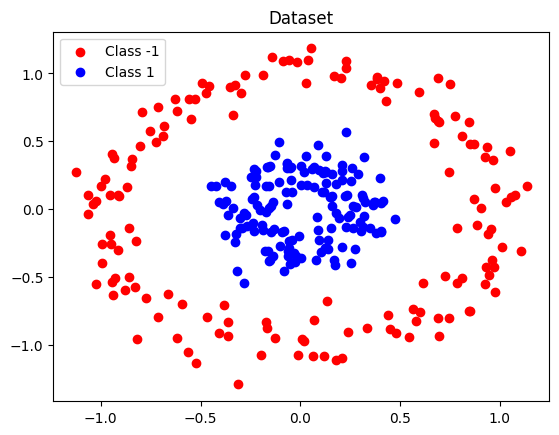

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# RBF kernel function
def rbf_kernel(X1, X2, sigma=1.0):
    """
    Function to compute the Gaussian Kernel (RBF)
    Input parameter:
    X1 shape (n_samples, n_features), X2 shape(n_samples, n_features) are the data
    sigma is the control parameter in the formula, default value is 1.0
    Output:
    The kernel matrix K(x_i, x_j)
    """
    #default value of sigma is 1.0. This means that if you do not pass the value for sigma, it will use the default value
    pairwise_sq_dists = np.sum(X1**2, axis=1).reshape(-1, 1) + np.sum(X2**2, axis=1) - 2 * np.dot(X1, X2.T)
    K = np.exp(-pairwise_sq_dists / (2 * sigma ** 2))
    return K

# Another way to define RBF Kernel by using norm directly.
def rbf_kernel2(X1, X2, sigma=1.0):
    K = np.exp(-np.linalg.norm(X1[:, np.newaxis] - X2[np.newaxis, :], axis=2) ** 2 / (2 * sigma ** 2))
    return K
    
# Logistic loss function
def logistic_loss(theta, K, y):
    """
    theta: the model parameter
    K: kernel function computed, its a matrix with shape n_samples x n_samples
    y: the target label
    """
    m = len(y)
    predictions = sigmoid(K @ theta)
    return -(1 / m) * np.sum(y * np.log(predictions + 1e-5) + (1 - y) * np.log(1 - predictions + 1e-5))

# Gradient of the logistic loss function
def logistic_gradient(theta, K, y):
    m = len(y)
    predictions = sigmoid(K @ theta)
    return (1 / m) * K.T @ (predictions - y)

# Gradient Descent Optimization
def gradient_descent(K, y, theta_init, lr=0.1, n_iters=10000):
    theta = theta_init
    loss_history = []
    
    for i in range(n_iters):
        # Compute loss and gradient
        loss = logistic_loss(theta, K, y)
        grad = logistic_gradient(theta, K, y)
        
        # Update theta
        theta -= lr * grad
        
        # Store loss
        loss_history.append(loss)
        
        # Print progress every 1000 iterations
        if i % 1000 == 0:
            print(f"Iteration {i}, Loss: {loss}")
    
    return theta, loss_history

# Generate toy data (e.g., circles)
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=300, factor=0.3, noise=0.1)
y = (y * 2) - 1  # Convert labels to {-1, 1}

print(X.shape, y.shape)
# Kernel matrix computation
sigma = 0.5
K = rbf_kernel(X, X, sigma)
print(K.shape)

# Plot the data
plt.scatter(X[y == -1][:, 0], X[y == -1][:, 1], color='red', label='Class -1')
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='blue', label='Class 1')
plt.title("Dataset")
plt.legend()
plt.show()

In [34]:
# Kernel matrix computation
sigma = 0.5
K = rbf_kernel(X, X, sigma)
print(K.shape)

# Logistic regression optimization using gradient descent
theta_init = np.zeros(X.shape[0])
learning_rate = 0.01
max_iterations = 10000
theta_optimal, loss_history = gradient_descent(K, y, theta_init, lr=learning_rate, n_iters=max_iterations)

# Prediction function
def predict(X_train, theta, X_new, sigma):
    K_new = rbf_kernel(X_train, X_new, sigma)
    predictions = sigmoid(K_new.T @ theta)
    return np.where(predictions >= 0.5, 1, -1)


(300, 300)
Iteration 0, Loss: 0.6931271807599427
Iteration 1000, Loss: -5.298641790111285
Iteration 2000, Loss: -4.99106651824024
Iteration 3000, Loss: -4.768654074017484
Iteration 4000, Loss: -4.610608806741768
Iteration 5000, Loss: -4.495046469840153
Iteration 6000, Loss: -4.404685113988451
Iteration 7000, Loss: -4.334710840797903
Iteration 8000, Loss: -4.283455573490043
Iteration 9000, Loss: -4.246088481425937


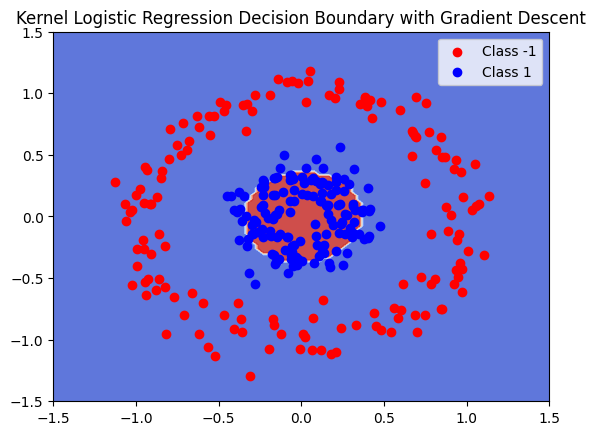

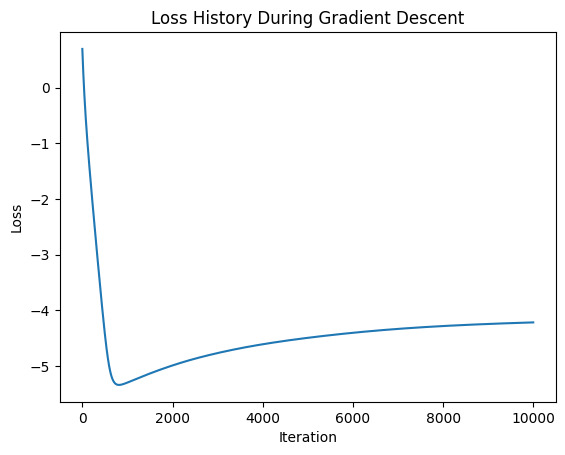

In [35]:
# Plot decision boundary
#create a meshgrid
xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 100), np.linspace(-1.5, 1.5, 100))
grid_points = np.c_[xx.ravel(), yy.ravel()]
# predict the probability from the kernel function, \sigmoid(K(x,x))=0.5
Z = predict(X, theta_optimal, grid_points, sigma)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.9, cmap=plt.cm.coolwarm)
plt.scatter(X[y == -1][:, 0], X[y == -1][:, 1], color='red', label='Class -1')
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='blue', label='Class 1')
plt.title("Kernel Logistic Regression Decision Boundary with Gradient Descent")
plt.legend()
plt.show()

# Plot loss history
plt.plot(loss_history)
plt.title("Loss History During Gradient Descent")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()